# MODELO ResNet50



In [1]:
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd()

# Datos locales
DATA_DIR = PROJECT_ROOT / "data"
IDRID_DIR = DATA_DIR / "IDRiD2"

# Archivos CSV
TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

# Directorios de imágenes
TRAIN_IMAGES_DIR = IDRID_DIR / "IDRiD" / "train" / "images"
TEST_IMAGES_DIR = IDRID_DIR / "IDRiD" / "test" / "images"

# Comprobar estructura
required_paths = [
    TRAIN_CSV,
    VAL_CSV,
    TRAIN_IMAGES_DIR,
    TEST_IMAGES_DIR
]

missing_paths = [
    path for path in required_paths
    if not path.exists()
]

if missing_paths:
    print("Faltan los siguientes archivos/directorios locales:")
    
    for path in missing_paths:
        print(f" - {path}")
    
    raise FileNotFoundError(
        "Completa la estructura local indicada antes de continuar."
    )

print("Proyecto local:", PROJECT_ROOT)
print("Dataset:", IDRID_DIR)
print("Configuración local correcta.")

Proyecto local: c:\Users\lauri\Documents\PROYECTO_FINAL
Dataset: c:\Users\lauri\Documents\PROYECTO_FINAL\data\IDRiD2
Configuración local correcta.


# Clasificación binaria de Retinopatía Diabética con RESNet50

# IMPORTACIONES Y CONFIGURACIÓN




In [2]:


# Dependencias
!pip -q install -U plotly kaleido



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



# IMPORTACIONES Y CONFIGURACIÓN


In [3]:


import os


import gc
import json
import math
import random
import shutil
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)


import tensorflow as tf
'''

para quitar

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision
'''



from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision


warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPUS = tf.config.list_physical_devices("GPU")

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if GPUS:
    mixed_precision.set_global_policy("mixed_float16")
else:
    mixed_precision.set_global_policy("float32")

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", GPUS)
print("Política de precisión:", mixed_precision.global_policy())

TensorFlow: 2.21.0
GPU disponibles: []
Política de precisión: <DTypePolicy "float32">


In [5]:
#2 CONFIGURACION DE RUTAS Y DIRECTORIOS

from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\lauri\Documents\PROYECTO_FINAL")

DATA_DIR = PROJECT_ROOT / "data"

TRAIN_CSV = DATA_DIR / "train_split.csv"
VAL_CSV = DATA_DIR / "val_split.csv"

TRAIN_IMAGE_ROOTS = [
    DATA_DIR / "IDRiD2" / "IDRiD" / "train" / "images"
]

TEST_IMAGES_DIR = (
    DATA_DIR / "IDRiD2" / "IDRiD" / "test" / "images"
)

OUTPUT_DIR = PROJECT_ROOT / "modelos" / "RESNet50" / "final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Parámetros generales

In [6]:
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 320
IMG_WIDTH = 320
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Valor seguro para GPU T4/P100.
BATCH_SIZE = 32 if GPUS else 8

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 12

HEAD_LEARNING_RATE = 1e-4
FINE_TUNE_LEARNING_RATE = 5e-6

UNFREEZE_LAST_LAYERS = 40
DROPOUT_RATE = 0.45


TARGET_SENSITIVITY = 0.90


# La caché guarda las imágenes redimensionadas en disco.
USE_DISK_CACHE = True

# Puede activarse si el entorno soporta XLA sin errores.
JIT_COMPILE = False

if Path("/kaggle/working").exists():
    WORK_ROOT = Path("/kaggle/working")
else:
    WORK_ROOT = Path.cwd()

RUN_DIR = WORK_ROOT / "ResNet50"
CACHE_DIR = RUN_DIR / "tf_cache"
LOG_DIR = RUN_DIR / "logs"

RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

HEAD_MODEL_PATH = RUN_DIR / "resnet50_phase1.keras"
FINETUNE_MODEL_PATH = RUN_DIR / "resnet50_phase2.keras"
FINAL_MODEL_PATH = RUN_DIR / "resnet50_final.keras"

HISTORY_PATH = RUN_DIR / "historial_entrenamiento.csv"
METRICS_PATH = RUN_DIR / "metricas_validacion.json"
THRESHOLD_PATH = RUN_DIR / "resnet50_threshold.json"
VALIDATION_PREDICTIONS_PATH = RUN_DIR / "predicciones_validacion.csv"
DASHBOARD_PATH = RUN_DIR / "dashboard_resnet50.html"

print("Directorio de resultados:", RUN_DIR)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


Directorio de resultados: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50
Tamaño de imagen: (320, 320)
Batch size: 8


# Limpieza del manifiesto


In [7]:
import pandas as pd
from pathlib import Path

train_path = Path("/data/train_split.csv")
val_path = Path("/data/val_split.csv")

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

# Identificar originales: el nombre de imagen coincide con patient_id.
train_df["is_original"] = train_df["Image name"].astype(str).eq(
    train_df["patient_id"].astype(str)
)
val_df["is_original"] = val_df["Image name"].astype(str).eq(
    val_df["patient_id"].astype(str)
)

train_df["model_split"] = "train"
val_df["model_split"] = "val"

# Validación rigurosa: solo imágenes originales.
val_originals_df = val_df[val_df["is_original"]].copy()

# Manifiesto combinado recomendado para RESNet50.
manifest_RESNet50 = pd.concat(
    [train_df, val_originals_df],
    ignore_index=True
)

train_out = Path("/data/train_split_RESNet50.csv")
val_out = Path("/data/val_split_RESNet50.csv")
combined_out = Path("/data/manifest_train_val_split_RESNet50.csv")

train_df.to_csv(train_out, index=False)
val_originals_df.to_csv(val_out, index=False)
manifest_RESNet50.to_csv(combined_out, index=False)

print(f"Train: {len(train_df)} filas, {train_df['patient_id'].nunique()} pacientes")
print(
    f"Validación original: {len(val_originals_df)} filas, "
    f"{val_originals_df['patient_id'].nunique()} pacientes"
)
print(f"Manifiesto combinado: {len(manifest_RESNet50)} filas")

Train: 2640 filas, 330 pacientes
Validación original: 83 filas, 83 pacientes
Manifiesto combinado: 2723 filas



# ÍNDICE ÚNICO DE IMÁGENES


In [8]:


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
}

IMAGE_ROOTS = [
    Path("data\\IDRiD2\\IDRiD\\train\\images"), 
    Path("data\\IDRiD2\\IDRiD\\test\\images"),
]

IMAGE_ROOTS = [
    root for root in IMAGE_ROOTS
    if root.exists()
]


def build_image_index(roots):
    """
    Recorre todos los directorios una sola vez.

    Retorna:
        {
            "idrid_001": [ruta1, ruta2],
            "idrid_001_r8": [ruta],
            ...
        }
    """
    image_index = {}
    total_images = 0

    for root in roots:
        print("Indexando:", root)

        for directory, _, filenames in os.walk(root):
            for filename in filenames:
                suffix = Path(filename).suffix.lower()

                if suffix not in IMAGE_EXTENSIONS:
                    continue

                full_path = Path(directory) / filename
                image_key = full_path.stem.lower().strip()

                image_index.setdefault(image_key, []).append(
                    str(full_path)
                )

                total_images += 1

    print("\nTotal de archivos de imagen encontrados:", total_images)
    print("Nombres únicos:", len(image_index))

    return image_index


image_index = build_image_index(IMAGE_ROOTS)

Indexando: data\IDRiD2\IDRiD\train\images
Indexando: data\IDRiD2\IDRiD\test\images

Total de archivos de imagen encontrados: 4128
Nombres únicos: 3304



# ASIGNAR image_path A LOS MANIFIESTOS


In [9]:


def image_path_score(path):
    """
    Si existe el mismo nombre en Training Set y Testing Set,
    prioriza la imagen procedente del conjunto de entrenamiento.
    """
    normalized = str(path).replace("\\", "/").lower()

    score = 0

    if "/train/" in normalized:
        score += 200

    if "training set" in normalized:
        score += 200

    if "/training/" in normalized:
        score += 150

    if "/images/" in normalized:
        score += 20

    if "augmented" in normalized:
        score += 500

    if "/test/" in normalized:
        score -= 200

    if "testing set" in normalized:
        score -= 200

    return score


def resolve_image_path(image_name):
    image_key = Path(str(image_name)).stem.lower().strip()
    candidates = image_index.get(image_key, [])

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda path: (
            image_path_score(path),
            -len(path),
        ),
    )


train_df["image_path"] = train_df["Image name"].map(
    resolve_image_path
)

val_df["image_path"] = val_df["Image name"].map(
    resolve_image_path
)

missing_train = train_df[
    train_df["image_path"].isna()
]

missing_val = val_df[
    val_df["image_path"].isna()
]

print("Imágenes faltantes en entrenamiento:", len(missing_train))
print("Imágenes faltantes en validación:", len(missing_val))

if len(missing_train) > 0:
    display(missing_train[["Image name"]].head(20))

if len(missing_val) > 0:
    display(missing_val[["Image name"]].head(20))

if len(missing_train) > 0 or len(missing_val) > 0:
    raise FileNotFoundError(
        "No fue posible localizar todas las imágenes. "
        "Revisa que el dataset de ENLACE-DATA esté agregado "
        "en la sección Input del notebook."
    )

# Verificar que no se esté utilizando el mismo archivo en ambos conjuntos.
shared_paths = set(train_df["image_path"]).intersection(
    set(val_df["image_path"])
)

if shared_paths:
    raise ValueError(
        f"Hay {len(shared_paths)} archivos compartidos entre "
        "entrenamiento y validación."
    )

print("\nEjemplos de rutas resueltas:")
display(
    train_df[
        ["Image name", "binary_label", "image_path"]
    ].head(5)
)

print(train_df["image_path"].head(5))
valor = train_df["image_path"].head(20).tolist()

# Abre el archivo en modo escritura ('w')
with open("prueba.txt", "w", encoding="utf-8") as archivo:
    archivo.write("\n".join(str(path) for path in valor))


Imágenes faltantes en entrenamiento: 0
Imágenes faltantes en validación: 0

Ejemplos de rutas resueltas:


,Image name,binary_label,image_path
0,IDRiD_001,1,data\IDRiD2\IDRiD\train\images\IDRiD_001.jpg
1,IDRiD_002,1,data\IDRiD2\IDRiD\train\images\IDRiD_002.jpg
2,IDRiD_004,1,data\IDRiD2\IDRiD\train\images\IDRiD_004.jpg
3,IDRiD_005,1,data\IDRiD2\IDRiD\train\images\IDRiD_005.jpg
4,IDRiD_006,1,data\IDRiD2\IDRiD\train\images\IDRiD_006.jpg


0    data\IDRiD2\IDRiD\train\images\IDRiD_001.jpg
1    data\IDRiD2\IDRiD\train\images\IDRiD_002.jpg
2    data\IDRiD2\IDRiD\train\images\IDRiD_004.jpg
3    data\IDRiD2\IDRiD\train\images\IDRiD_005.jpg
4    data\IDRiD2\IDRiD\train\images\IDRiD_006.jpg
Name: image_path, dtype: str



# COMPROBACIÓN RÁPIDA DE DECODIFICACIÓN


In [10]:


sample_paths = pd.concat(
    [
        train_df["image_path"].sample(
            min(8, len(train_df)),
            random_state=SEED,
        ),
        val_df["image_path"].sample(
            min(4, len(val_df)),
            random_state=SEED,
        ),
    ],
    ignore_index=True,
)

decode_errors = []

for image_path in sample_paths:
    try:
        image_bytes = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False,
        )

        if image.shape[-1] != 3:
            decode_errors.append(image_path)

    except Exception as error:
        decode_errors.append(
            (image_path, str(error))
        )

if decode_errors:
    print("Archivos con problemas:")
    print(decode_errors)
else:
    print(
        f"Comprobación exitosa: "
        f"{len(sample_paths)} imágenes decodificadas."
    )

Comprobación exitosa: 12 imágenes decodificadas.



#COMPROBACIÓN RÁPIDA DE DECODIFICACIÓN




,Entrenamiento,Validación
No referible,984,31
Referible,1656,52


Pesos de clase: {0: 1.3414634146341464, 1: 0.7971014492753623}


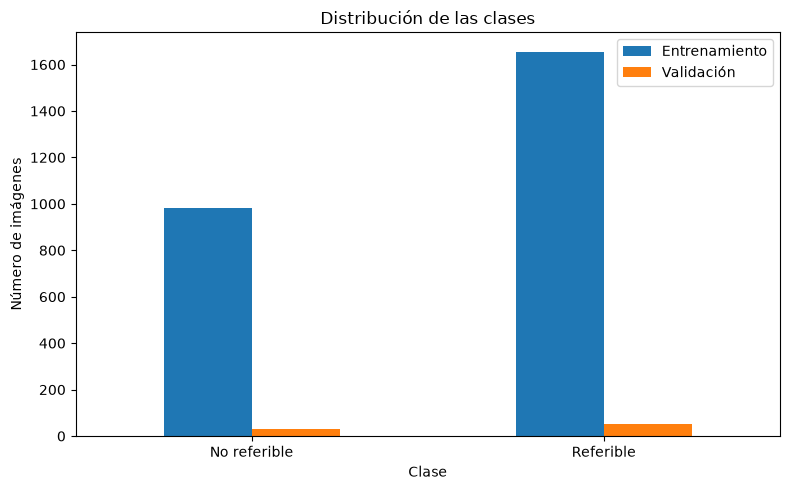

In [11]:

train_distribution = (
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

val_distribution = (
    val_df["binary_label"]
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "Entrenamiento": train_distribution,
    "Validación": val_distribution,
}).fillna(0).astype(int)

distribution_df.index = [
    CLASS_NAMES[int(label)]
    for label in distribution_df.index
]

display(distribution_df)

classes = np.array([0, 1], dtype=np.int32)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["binary_label"].to_numpy(),
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Pesos de clase:", CLASS_WEIGHT)

distribution_df.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribución de las clases",
)

plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# PIPELINE

In [12]:


AUTOTUNE = tf.data.AUTOTUNE


def dataset_fingerprint(dataframe):
    content = "\n".join(
        dataframe["image_path"].astype(str)
        + "|"
        + dataframe["binary_label"].astype(str)
    )

    return hashlib.md5(
        content.encode("utf-8")
    ).hexdigest()[:12]


def decode_and_resize(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    # Mantiene la proporción de la retina sin deformarla.
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        clip_value_min=0.0,
        clip_value_max=255.0,
    )

    # Cachear uint8 consume aproximadamente 4 veces menos espacio.
    image = tf.cast(image, tf.uint8)
    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(
    dataframe,
    training=False,
    cache_name=None,
):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["binary_label"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training,
    )

    if USE_DISK_CACHE and cache_name is not None:
        fingerprint = dataset_fingerprint(dataframe)

        cache_path = CACHE_DIR / (
            f"{cache_name}_{fingerprint}_"
            f"{IMG_HEIGHT}x{IMG_WIDTH}"
        )

        dataset = dataset.cache(str(cache_path))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(
    train_df,
    training=True,
    cache_name="train",
)

val_ds = make_dataset(
    val_df,
    training=False,
    cache_name="val",
)

print("Pipeline de entrenamiento:", train_ds)
print("Pipeline de validación:", val_ds)

Pipeline de entrenamiento: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 320, 320, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>
Pipeline de validación: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 320, 320, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>



# REVISIÓN UN SOLO LOTE


Forma de las imágenes: (8, 320, 320, 3)
Tipo de dato: <dtype: 'uint8'>
Forma de etiquetas: (8,)
Rango: 0 254


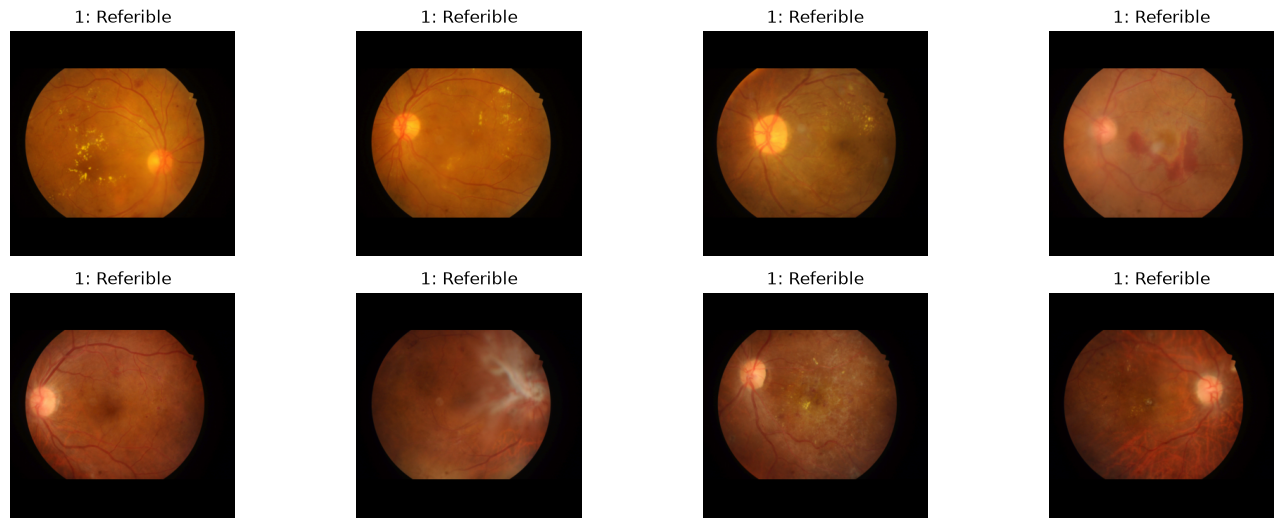

In [13]:
# Creamos un minidataset temporal sin caché ni mezcla para que la revisión sea instantánea
quick_check_ds = make_dataset(
    train_df.head(BATCH_SIZE),
    training=False,
    cache_name=None,
)

batch_images, batch_labels = next(
    iter(quick_check_ds.take(1))
)

print("Forma de las imágenes:", batch_images.shape)
print("Tipo de dato:", batch_images.dtype)
print("Forma de etiquetas:", batch_labels.shape)
print("Rango:", batch_images.numpy().min(), batch_images.numpy().max())

plt.figure(figsize=(14, 8))

images_to_show = min(12, len(batch_images))

for index in range(images_to_show):
    plt.subplot(3, 4, index + 1)

    plt.imshow(
        batch_images[index].numpy().astype(np.uint8)
    )

    label = int(batch_labels[index].numpy())

    plt.title(
        f"{label}: {CLASS_NAMES[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# MODELO RESNet50


In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_HEIGHT = 320
IMG_WIDTH = 320
DROPOUT_RATE = 0.45
SEED = 42

# ============================================================
# RESNET50 SIN DATA AUGMENTATION
# ============================================================

base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

base_model.trainable = False

inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="image"
)

# ============================================================
# PREPROCESAMIENTO DE RESNET50
# NO se aplica Data Augmentation
# ============================================================

x = tf.keras.applications.resnet50.preprocess_input(inputs)

# Mantiene BatchNormalization estable
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    DROPOUT_RATE,
    name="head_dropout"
)(x)

# ============================================================
# CAPA DENSA 256
# ============================================================

x = layers.Dense(
    256,
    activation="swish",
    kernel_regularizer=tf.keras.regularizers.l2(5e-4),
    name="dense_256"
)(x)

x = layers.BatchNormalization(
    name="bn_256"
)(x)

x = layers.Dropout(
    0.45,
    name="dropout_256"
)(x)

# ============================================================
# CAPA DENSA 128
# ============================================================

x = layers.Dense(
    128,
    activation="swish",
    kernel_regularizer=tf.keras.regularizers.l2(5e-4),
    name="dense_128"
)(x)

x = layers.BatchNormalization(
    name="bn_128"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout_128"
)(x)

# ============================================================
# CAPA DENSA 64
# ============================================================

x = layers.Dense(
    64,
    activation="swish",
    kernel_regularizer=tf.keras.regularizers.l2(5e-4),
    name="dense_64"
)(x)

x = layers.BatchNormalization(
    name="bn_64"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout_64"
)(x)

# ============================================================
# SALIDA BINARIA
# ============================================================

outputs = layers.Dense(
    1,
    activation="sigmoid",

    # Evita inestabilidad numérica con mixed precision
    dtype="float32",
    name="prediction"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_Clinical_DR"
)

# ============================================================
# MÉTRICAS
# ============================================================

def diagnostic_metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="sensitivity"
        ),

        tf.keras.metrics.AUC(
            name="auc",
            curve="ROC",
            num_thresholds=300
        ),

        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR",
            num_thresholds=500
        ),

        tf.keras.metrics.SpecificityAtSensitivity(
            sensitivity=TARGET_SENSITIVITY,
            num_thresholds=500,
            name="specificity_at_sensitivity_90"
        )
    ]

# ============================================================
# OPTIMIZADOR
# ============================================================

def create_optimizer(learning_rate, weight_decay):
    return keras.optimizers.AdamW(
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        clipnorm=1.0,
    )

# ============================================================
# COMPILACIÓN
# ============================================================

def compile_model(model_to_compile, learning_rate, weight_decay):

    compile_arguments = dict(
        optimizer=create_optimizer(
            learning_rate,
            weight_decay
        ),

        loss=keras.losses.BinaryCrossentropy(
            label_smoothing=0.01
        ),

        metrics=diagnostic_metrics(),

        steps_per_execution=5,
    )

    if JIT_COMPILE:
        compile_arguments["jit_compile"] = True

    model_to_compile.compile(
        **compile_arguments
    )


compile_model(
    model,
    learning_rate=HEAD_LEARNING_RATE,
    weight_decay=5e-4,
)

model.summary()

Model: "ResNet50_Clinical_DR"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 320, 320)  │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 320, 320)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 320, 320)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 320, 320,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 320, 320,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 10, 10,    │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 2048)      │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_256 (Dense)   │ (None, 256)       │    524,544 │ head_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_256              │ (None, 256)       │      1,024 │ dense_256[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_256         │ (None, 256)       │          0 │ bn_256[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │     32,896 │ dropout_256[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_128              │ (None, 128)       │        512 │ dense_128[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_128         │ (None, 128)       │          0 │ bn_128[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 64)        │      8,256 │ dropout_128[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_64               │ (None, 64)        │        256 │ dense_64[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_64          │ (None, 64)        │          0 │ bn_64[0][0]     

 Total params: 24,155,265 (92.15 MB)

 Trainable params: 566,657 (2.16 MB)

 Non-trainable params: 23,588,608 (89.98 MB)

In [15]:

print("Nombre del backbone:", base_model.name)
print("Backbone entrenable:", base_model.trainable)
print("Cantidad de pesos:", len(base_model.weights))
print("Cantidad de parámetros:", base_model.count_params())

Nombre del backbone: resnet50
Backbone entrenable: False
Cantidad de pesos: 318
Cantidad de parámetros: 23587712


In [16]:
if 'model' in locals():
    print("Capas en el modelo principal:", len(model.layers))
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            print(f"Capas dentro del submodelo '{layer.name}':", len(layer.layers))
else:
    print("El modelo no está definido. Por favor, ejecuta las celdas anteriores primero.")

Capas en el modelo principal: 14
Capas dentro del submodelo 'resnet50': 175


#  CALLBACKS

In [17]:
def create_callbacks(phase_name, model_path, patience=3):

    phase_log_path = LOG_DIR / (
        f"{phase_name}_training_log.csv"
    )

    backup_path = RUN_DIR / (
        f"backup_{phase_name}"
    )
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(model_path),
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=patience,
            min_delta=0.001,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.30,
            patience=2,
            min_lr=1e-7,
            verbose=1
        ),

        keras.callbacks.CSVLogger(
            filename=str(phase_log_path),
            append=False,
        ),

        keras.callbacks.BackupAndRestore(
            backup_dir=str(backup_path),
        ),

        tf.keras.callbacks.TerminateOnNaN()
    ]


# ENTRENAR SOLO LA CABEZA

In [18]:
head_callbacks = create_callbacks(
    phase_name="Cabecera",
    model_path = HEAD_MODEL_PATH,
    patience=4,
)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=head_callbacks,
    verbose=1,
)

print("Mejor modelo de la fase 1:")
print(HEAD_MODEL_PATH)

Epoch 1/8


330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 775ms/step - accuracy: 0.6133 - auc: 0.6805 - loss: 1.1107 - pr_auc: 0.7626 - precision: 0.7354 - sensitivity: 0.5990 - specificity_at_sensitivity_90: 0.2876
Epoch 1: val_auc improved from None to 0.95037, saving model to c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_phase1.keras

Epoch 1: finished saving model to c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_phase1.keras
330/330 ━━━━━━━━━━━━━━━━━━━━ 267s 808ms/step - accuracy: 0.6133 - auc: 0.6805 - loss: 1.1107 - pr_auc: 0.7626 - precision: 0.7354 - sensitivity: 0.5990 - specificity_at_sensitivity_90: 0.2876 - val_accuracy: 0.8916 - val_auc: 0.9504 - val_loss: 0.6862 - val_pr_auc: 0.9674 - val_precision: 0.8644 - val_sensitivity: 0.9808 - val_specificity_at_sensitivity_90: 0.8387 - learning_rate: 1.0000e-04
Epoch 2/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.7106 - auc: 0.8023 - loss: 0.9478 - pr_auc: 0.8670 - precision: 0.8260 - sensitivity: 0.6824 - specificity_

# FINE-TUNING


In [19]:
# Partir del mejor modelo de la fase congelada.
model = keras.models.load_model(
    HEAD_MODEL_PATH
)

backbone = model.get_layer(
    "resnet50"
)

backbone.trainable = True

# Fine-tuning conservador: solo el último bloque residual.
for layer in backbone.layers:
    layer.trainable = layer.name.startswith(
        "conv5_block3"
    )

    # Nunca actualizar estadísticas BatchNormalization con un dataset pequeño.
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

trainable_backbone_layers = sum(
    int(layer.trainable)
    for layer in backbone.layers
)

print(
    "Capas entrenables del backbone:",
    trainable_backbone_layers,
)

compile_model(
    model,
    learning_rate=FINE_TUNE_LEARNING_RATE,
    weight_decay=1e-4,
)

finetune_callbacks = create_callbacks(
    phase_name="finetune",
    model_path=FINETUNE_MODEL_PATH,
    patience=4,
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=finetune_callbacks,
    verbose=1,
)
'''
# Partimos del mejor modelo de la primera fase.
model = keras.models.load_model(
    HEAD_MODEL_PATH
)

backbone = model.get_layer(
    "resnet50"
)

backbone.trainable = True

# Congelar todas las capas excepto las últimas.
for layer in backbone.layers[:-UNFREEZE_LAST_LAYERS]:
    layer.trainable = False

# Mantener BatchNormalization congelada durante fine-tuning.
for layer in backbone.layers[-UNFREEZE_LAST_LAYERS:]:
    if isinstance(
        layer,
        keras.layers.BatchNormalization,
    ):
        layer.trainable = False

trainable_backbone_layers = sum(
    int(layer.trainable)
    for layer in backbone.layers
)

print(
    "Capas entrenables del backbone:",
    trainable_backbone_layers,
)

compile_model(
    model,
    learning_rate=FINE_TUNE_LEARNING_RATE,
)

finetune_callbacks = create_callbacks(
    phase_name="finetune",
    model_path=FINETUNE_MODEL_PATH,
    patience=4,
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=CLASS_WEIGHT,
    callbacks=finetune_callbacks,
    verbose=1,
)'''

Capas entrenables del backbone: 7
Epoch 1/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.7845 - auc: 0.8711 - loss: 0.8257 - pr_auc: 0.9224 - precision: 0.8720 - sensitivity: 0.7693 - specificity_at_sensitivity_90: 0.5843
Epoch 1: val_auc improved from None to 0.98511, saving model to c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_phase2.keras

Epoch 1: finished saving model to c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_phase2.keras
330/330 ━━━━━━━━━━━━━━━━━━━━ 200s 606ms/step - accuracy: 0.7845 - auc: 0.8711 - loss: 0.8257 - pr_auc: 0.9224 - precision: 0.8720 - sensitivity: 0.7693 - specificity_at_sensitivity_90: 0.5843 - val_accuracy: 0.9157 - val_auc: 0.9851 - val_loss: 0.5351 - val_pr_auc: 0.9914 - val_precision: 0.9091 - val_sensitivity: 0.9615 - val_specificity_at_sensitivity_90: 0.9677 - learning_rate: 5.0000e-06
Epoch 2/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.8159 - auc: 0.8928 - loss: 0.7833 - pr_auc: 0.9315 - precisio

'\n# Partimos del mejor modelo de la primera fase.\nmodel = keras.models.load_model(\n    HEAD_MODEL_PATH\n)\n\nbackbone = model.get_layer(\n    "resnet50"\n)\n\nbackbone.trainable = True\n\n# Congelar todas las capas excepto las últimas.\nfor layer in backbone.layers[:-UNFREEZE_LAST_LAYERS]:\n    layer.trainable = False\n\n# Mantener BatchNormalization congelada durante fine-tuning.\nfor layer in backbone.layers[-UNFREEZE_LAST_LAYERS:]:\n    if isinstance(\n        layer,\n        keras.layers.BatchNormalization,\n    ):\n        layer.trainable = False\n\ntrainable_backbone_layers = sum(\n    int(layer.trainable)\n    for layer in backbone.layers\n)\n\nprint(\n    "Capas entrenables del backbone:",\n    trainable_backbone_layers,\n)\n\ncompile_model(\n    model,\n    learning_rate=FINE_TUNE_LEARNING_RATE,\n)\n\nfinetune_callbacks = create_callbacks(\n    phase_name="finetune",\n    model_path=FINETUNE_MODEL_PATH,\n    patience=4,\n)\n\nhistory_finetune = model.fit(\n    train_ds,\n  

# COMPARAR FASE 1 VS FINE-TUNING

In [20]:
#

candidate_paths = [
    HEAD_MODEL_PATH,
    FINETUNE_MODEL_PATH,
]

comparison_results = []

for candidate_path in candidate_paths:
    candidate_model = keras.models.load_model(
        candidate_path
    )

    candidate_metrics = candidate_model.evaluate(
        val_ds,
        return_dict=True,
        verbose=0,
    )

    comparison_results.append({
        "model_path": str(candidate_path),
        **{
            metric_name: float(metric_value)
            for metric_name, metric_value
            in candidate_metrics.items()
        },
    })

    del candidate_model
    gc.collect()

comparison_df = pd.DataFrame(
    comparison_results
)

display(
    comparison_df.sort_values(
        "pr_auc",
        ascending=False,
    )
)

best_row = comparison_df.sort_values(
    "pr_auc",
    ascending=False,
).iloc[0]

BEST_CANDIDATE_PATH = Path(
    best_row["model_path"]
)

model = keras.models.load_model(
    BEST_CANDIDATE_PATH
)

model.save(
    FINAL_MODEL_PATH,
    overwrite=True,
)

print("Mejor candidato:", BEST_CANDIDATE_PATH)
print("Modelo final guardado en:", FINAL_MODEL_PATH)

,model_path,accuracy,auc,loss,pr_auc,precision,sensitivity,specificity_at_sensitivity_90
1,c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet...,0.927711,0.987593,0.526245,0.993061,0.925926,0.961538,1.000000
0,c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet...,0.915663,0.983561,0.541523,0.990158,0.909091,0.961538,0.967742


Mejor candidato: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_phase2.keras
Modelo final guardado en: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_final.keras



# HISTORIAL DE ENTRENAMIENTO


,epoch,accuracy,auc,loss,pr_auc,precision,sensitivity,specificity_at_sensitivity_90,val_accuracy,val_auc,val_loss,val_pr_auc,val_precision,val_sensitivity,val_specificity_at_sensitivity_90,learning_rate,phase
10,11,0.810985,0.897973,0.768775,0.940729,0.894881,0.791667,0.669715,0.927711,0.987593,0.526245,0.993061,0.925926,0.961538,1.000000,0.000005,Fine-tuning
11,12,0.823864,0.911007,0.742964,0.946713,0.904827,0.803744,0.698171,0.915663,0.986663,0.523512,0.992396,0.909091,0.961538,1.000000,0.000005,Fine-tuning
12,13,0.834848,0.916222,0.729376,0.948816,0.911051,0.816425,0.734756,0.915663,0.986973,0.517938,0.992728,0.909091,0.961538,0.967742,0.000005,Fine-tuning
13,14,0.851515,0.929990,0.695384,0.959713,0.927605,0.827899,0.802846,0.927711,0.986973,0.512113,0.992869,0.910714,0.980769,0.967742,0.000005,Fine-tuning
14,15,0.848864,0.927928,0.700459,0.956342,0.916501,0.835145,0.777439,0.915663,0.986973,0.517867,0.992767,0.909091,0.961538,0.967742,0.000005,Fine-tuning


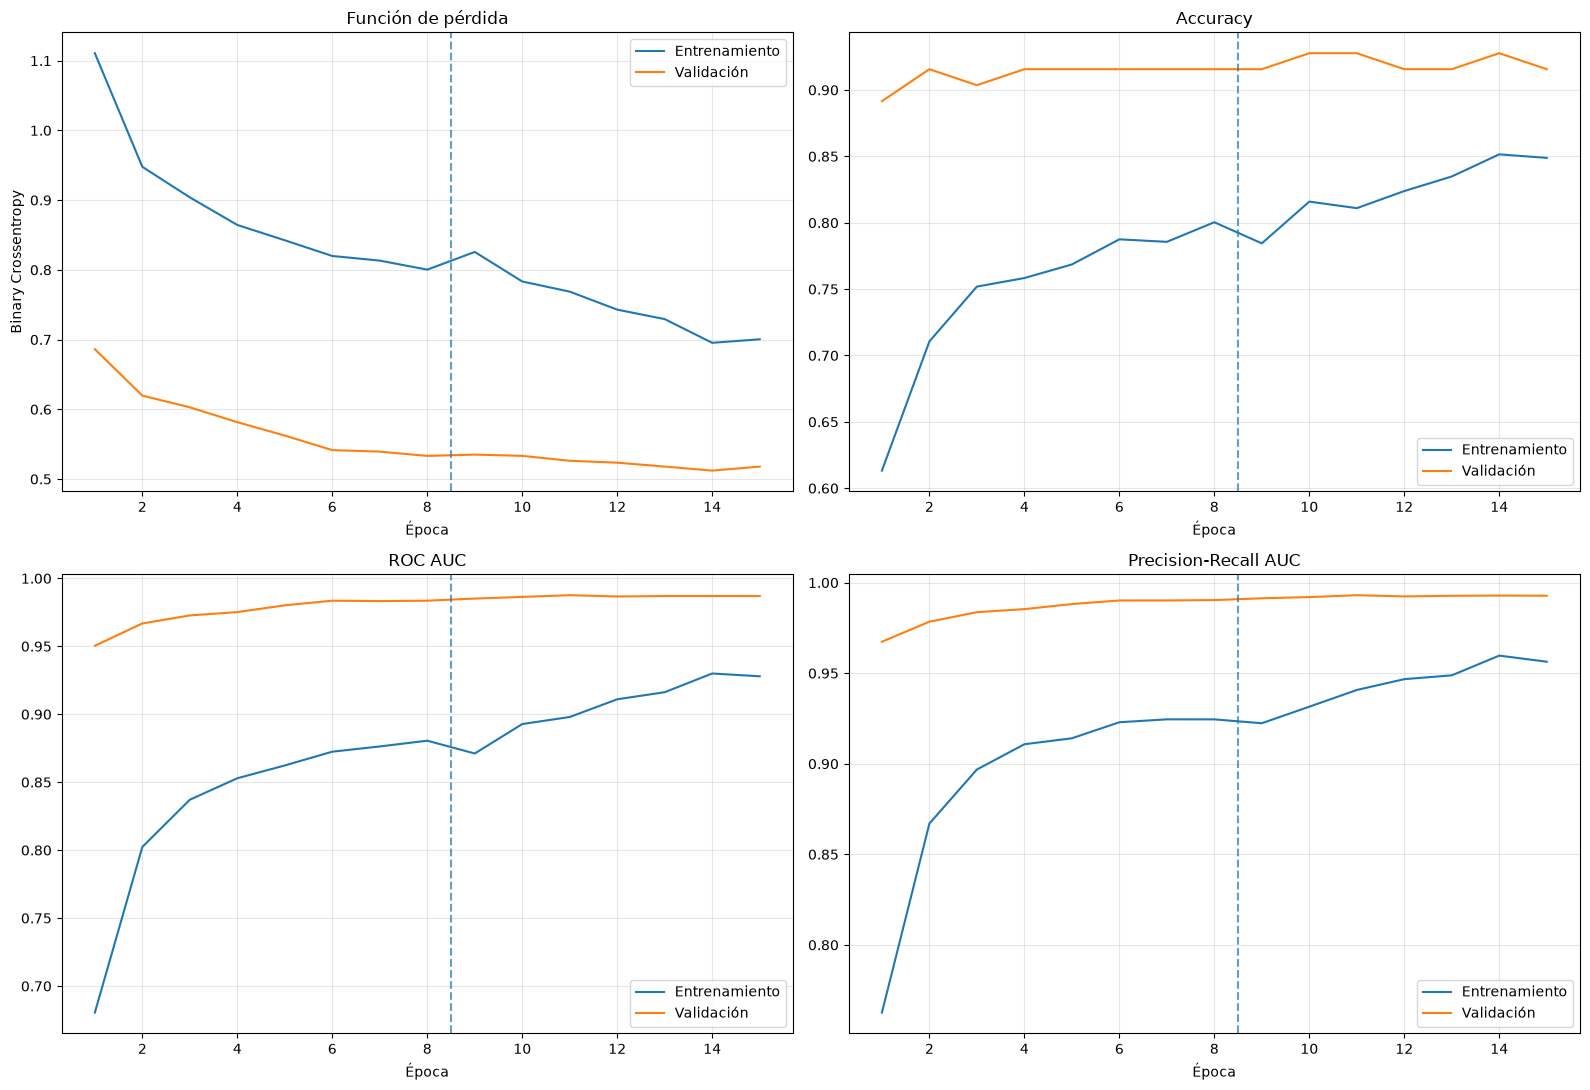

In [21]:
head_history_df = pd.DataFrame(
    history_head.history
)

head_history_df["phase"] = "Cabeza"

finetune_history_df = pd.DataFrame(
    history_finetune.history
)

finetune_history_df["phase"] = "Fine-tuning"

history_df = pd.concat(
    [
        head_history_df,
        finetune_history_df,
    ],
    ignore_index=True,
)

history_df.insert(
    0,
    "epoch",
    np.arange(1, len(history_df) + 1),
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(history_df.tail())

phase_boundary = len(head_history_df)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
)

# Pérdida
axes[0, 0].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Entrenamiento",
)

axes[0, 0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validación",
)

axes[0, 0].set_title("Función de pérdida")
axes[0, 0].set_xlabel("Época")
axes[0, 0].set_ylabel("Binary Crossentropy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Accuracy
axes[0, 1].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Entrenamiento",
)

axes[0, 1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validación",
)

axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Época")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# ROC AUC
axes[1, 0].plot(
    history_df["epoch"],
    history_df["auc"],
    label="Entrenamiento",
)

axes[1, 0].plot(
    history_df["epoch"],
    history_df["val_auc"],
    label="Validación",
)

axes[1, 0].set_title("ROC AUC")
axes[1, 0].set_xlabel("Época")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# PR AUC
axes[1, 1].plot(
    history_df["epoch"],
    history_df["pr_auc"],
    label="Entrenamiento",
)

axes[1, 1].plot(
    history_df["epoch"],
    history_df["val_pr_auc"],
    label="Validación",
)

axes[1, 1].set_title("Precision-Recall AUC")
axes[1, 1].set_xlabel("Época")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

for axis in axes.flat:
    axis.axvline(
        phase_boundary + 0.5,
        linestyle="--",
        alpha=0.7,
        label="Inicio fine-tuning",
    )

plt.tight_layout()
plt.show()

#PREDICCIONES DE VALIDACIÓN Y UMBRAL

In [22]:
# ============================================================
# CELDA 17: PREDICCIONES DE VALIDACIÓN Y UMBRAL
# ============================================================

model = keras.models.load_model(
    FINAL_MODEL_PATH
)

y_true = (
    val_df["binary_label"]
    .astype(int)
    .to_numpy()
)

y_probability = (
    model.predict(
        val_ds,
        verbose=1,
    )
    .reshape(-1)
)

if len(y_probability) != len(y_true):
    raise ValueError(
        "La cantidad de predicciones no coincide con "
        "el número de filas de validación."
    )

# ------------------------------------------------------------
# Umbral que maximiza F1
# ------------------------------------------------------------

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_true,
        y_probability,
    )
)

if len(pr_thresholds) > 0:
    f1_values = (
        2
        * precision_values[:-1]
        * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-8
        )
    )

    best_f1_index = int(
        np.nanargmax(f1_values)
    )

    THRESHOLD_F1 = float(
        pr_thresholds[best_f1_index]
    )
else:
    THRESHOLD_F1 = 0.5

# ------------------------------------------------------------
# Umbral alternativo para sensibilidad mínima de 90 %
# ------------------------------------------------------------

TARGET_SENSITIVITY = 0.90

fpr_values, tpr_values, roc_thresholds = roc_curve(
    y_true,
    y_probability,
)

valid_indices = np.where(
    tpr_values >= TARGET_SENSITIVITY
)[0]

if len(valid_indices) > 0:
    best_sensitivity_index = valid_indices[
        np.argmin(fpr_values[valid_indices])
    ]

    THRESHOLD_SENSITIVITY = float(
        np.clip(
            roc_thresholds[best_sensitivity_index],
            0.0,
            1.0,
        )
    )
else:
    THRESHOLD_SENSITIVITY = 0.5

# Umbral usado por defecto para la clasificación.
SELECTED_THRESHOLD = THRESHOLD_F1

print("Umbral estándar:", 0.5)
print("Umbral con mejor F1:", round(THRESHOLD_F1, 4))
print(
    "Umbral para sensibilidad >= 90 %:",
    round(THRESHOLD_SENSITIVITY, 4),
)
print(
    "Umbral seleccionado:",
    round(SELECTED_THRESHOLD, 4),
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step       
Umbral estándar: 0.5
Umbral con mejor F1: 0.6315
Umbral para sensibilidad >= 90 %: 0.6933
Umbral seleccionado: 0.6315



# MÉTRICAS BINARIAS



In [23]:


def calculate_binary_metrics(
    true_labels,
    probabilities,
    threshold,
):
    predicted_labels = (
        probabilities >= threshold
    ).astype(int)

    matrix = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1],
    )

    tn, fp, fn, tp = matrix.ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    negative_predictive_value = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "accuracy": float(
            accuracy_score(
                true_labels,
                predicted_labels,
            )
        ),
        "precision": float(
            precision_score(
                true_labels,
                predicted_labels,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity),
        "f1_score": float(
            f1_score(
                true_labels,
                predicted_labels,
                zero_division=0,
            )
        ),
        "npv": float(negative_predictive_value),
        "roc_auc": float(
            roc_auc_score(
                true_labels,
                probabilities,
            )
        ),
        "pr_auc": float(
            average_precision_score(
                true_labels,
                probabilities,
            )
        ),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


metrics_threshold_05 = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=0.5,
)

metrics_selected = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=SELECTED_THRESHOLD,
)

metrics_sensitivity = calculate_binary_metrics(
    y_true,
    y_probability,
    threshold=THRESHOLD_SENSITIVITY,
)

metrics_comparison = pd.DataFrame(
    [
        {
            "Configuración": "Umbral 0.50",
            **metrics_threshold_05,
        },
        {
            "Configuración": "Mejor F1",
            **metrics_selected,
        },
        {
            "Configuración": "Sensibilidad >= 90 %",
            **metrics_sensitivity,
        },
    ]
)

display(
    metrics_comparison[
        [
            "Configuración",
            "threshold",
            "accuracy",
            "precision",
            "sensitivity_recall",
            "specificity",
            "f1_score",
            "roc_auc",
            "pr_auc",
        ]
    ]
)

y_pred_selected = (
    y_probability >= SELECTED_THRESHOLD
).astype(int)

print(
    classification_report(
        y_true,
        y_pred_selected,
        labels=[0, 1],
        target_names=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        digits=4,
        zero_division=0,
    )
)

,Configuración,threshold,accuracy,precision,sensitivity_recall,specificity,f1_score,roc_auc,pr_auc
0,Umbral 0.50,0.500000,0.927711,0.925926,0.961538,0.870968,0.943396,0.987593,0.993123
1,Mejor F1,0.631538,0.939759,0.960784,0.942308,0.935484,0.951456,0.987593,0.993123
2,Sensibilidad >= 90 %,0.693308,0.939759,1.000000,0.903846,1.000000,0.949495,0.987593,0.993123


              precision    recall  f1-score   support

No referible     0.9062    0.9355    0.9206        31
   Referible     0.9608    0.9423    0.9515        52

    accuracy                         0.9398        83
   macro avg     0.9335    0.9389    0.9360        83
weighted avg     0.9404    0.9398    0.9399        83




# GRÁFICAS DE EVALUACIÓN


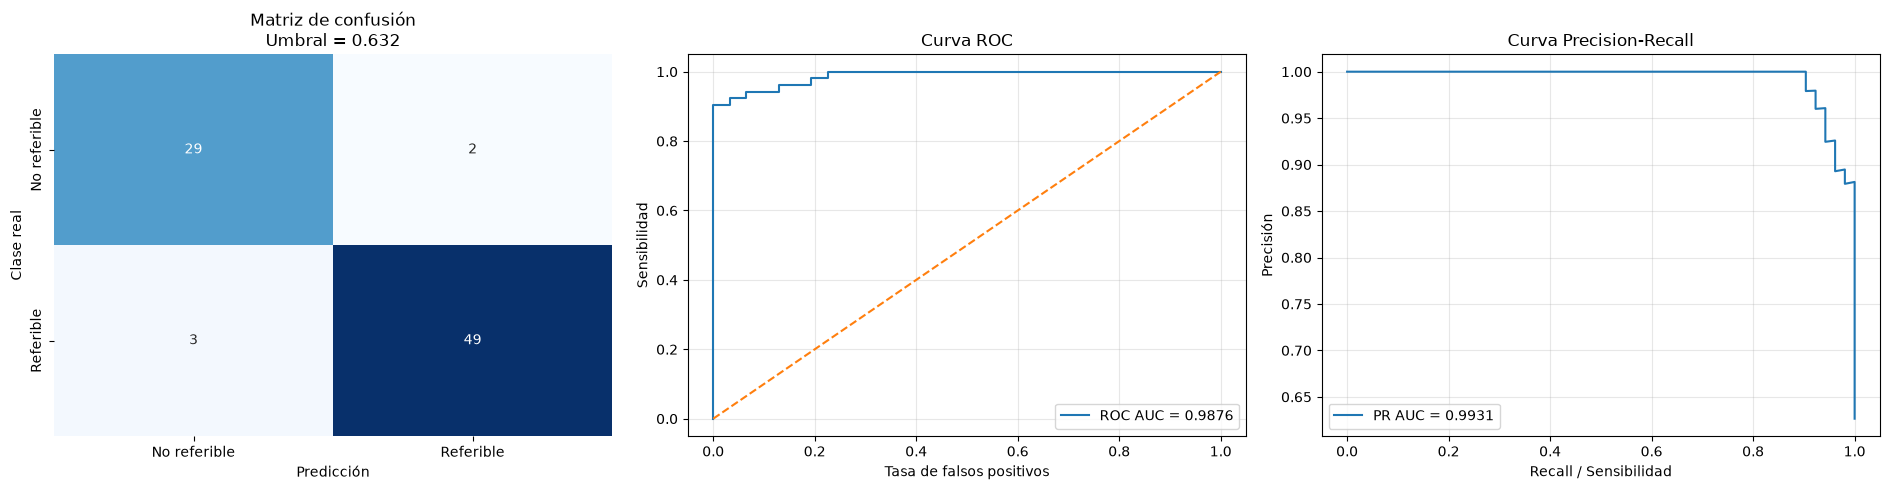

In [24]:


cm_selected = confusion_matrix(
    y_true,
    y_pred_selected,
    labels=[0, 1],
)

fpr_curve, tpr_curve, _ = roc_curve(
    y_true,
    y_probability,
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_true,
        y_probability,
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5),
)

sns.heatmap(
    cm_selected,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    yticklabels=[
        CLASS_NAMES[0],
        CLASS_NAMES[1],
    ],
    ax=axes[0],
)

axes[0].set_title(
    f"Matriz de confusión\n"
    f"Umbral = {SELECTED_THRESHOLD:.3f}"
)

axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase real")

axes[1].plot(
    fpr_curve,
    tpr_curve,
    label=(
        f"ROC AUC = "
        f"{metrics_selected['roc_auc']:.4f}"
    ),
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Sensibilidad")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    recall_curve,
    precision_curve,
    label=(
        f"PR AUC = "
        f"{metrics_selected['pr_auc']:.4f}"
    ),
)

axes[2].set_title("Curva Precision-Recall")
axes[2].set_xlabel("Recall / Sensibilidad")
axes[2].set_ylabel("Precisión")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# GUARDAR RESULTADOS



In [25]:

validation_predictions_df = val_df[
    [
        "Image name",
        "patient_id",
        "binary_label",
        "image_path",
    ]
].copy()

validation_predictions_df[
    "probability_referable"
] = y_probability

validation_predictions_df[
    "predicted_label"
] = y_pred_selected

validation_predictions_df[
    "predicted_class"
] = validation_predictions_df[
    "predicted_label"
].map(CLASS_NAMES)

validation_predictions_df[
    "correct_prediction"
] = (
    validation_predictions_df["binary_label"]
    == validation_predictions_df["predicted_label"]
)

validation_predictions_df.to_csv(
    VALIDATION_PREDICTIONS_PATH,
    index=False,
)

metrics_payload = {
    "class_names": CLASS_NAMES,
    "selected_threshold": float(
        SELECTED_THRESHOLD
    ),
    "threshold_f1": float(
        THRESHOLD_F1
    ),
    "threshold_sensitivity_90": float(
        THRESHOLD_SENSITIVITY
    ),
    "metrics_threshold_0_5": metrics_threshold_05,
    "metrics_selected_threshold": metrics_selected,
    "metrics_sensitivity_90": metrics_sensitivity,
    "best_candidate_model": str(
        BEST_CANDIDATE_PATH
    ),
    "final_model": str(
        FINAL_MODEL_PATH
    ),
}

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metrics_payload,
        file,
        indent=4,
        ensure_ascii=False,
    )

with open(
    THRESHOLD_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "threshold": float(
                SELECTED_THRESHOLD
            ),
            "class_0": CLASS_NAMES[0],
            "class_1": CLASS_NAMES[1],
        },
        file,
        indent=4,
        ensure_ascii=False,
    )

print("Predicciones:", VALIDATION_PREDICTIONS_PATH)
print("Métricas:", METRICS_PATH)
print("Umbral:", THRESHOLD_PATH)

Predicciones: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\predicciones_validacion.csv
Métricas: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\metricas_validacion.json
Umbral: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\resnet50_threshold.json


In [28]:
# ============================================================
# GUARDAR Y EXPORTAR MODELO RESNET50 ENTRENADO
# ============================================================

from pathlib import Path
import shutil

# Detectar entorno
try:
    from google.colab import files
    EN_COLAB = True
    OUTPUT_DIR = Path("/content/ResNet50")

except ImportError:
    EN_COLAB = False
    OUTPUT_DIR = Path.cwd() / "ResNet50"

# Crear carpeta de resultados
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. GUARDAR MODELO ENTRENADO
# ============================================================

FINAL_MODEL_PATH = OUTPUT_DIR / "ResNet50_modelo_final.keras"

model.save(str(FINAL_MODEL_PATH))

print("Modelo guardado correctamente:")
print(FINAL_MODEL_PATH)

# ============================================================
# 2. COMPRIMIR CARPETA COMPLETA DE RESULTADOS
# ============================================================

ZIP_PATH = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=str(OUTPUT_DIR.parent),
    base_dir=OUTPUT_DIR.name
)

print("\nCarpeta comprimida correctamente:")
print(ZIP_PATH)

# ============================================================
# 3. DESCARGAR ARCHIVOS
# ============================================================

if EN_COLAB:

    print("\nDescargando modelo entrenado...")
    files.download(str(FINAL_MODEL_PATH))

    print("\nDescargando carpeta comprimida...")
    files.download(ZIP_PATH)

else:

    print("\nArchivos guardados localmente.")
    print("Modelo:", FINAL_MODEL_PATH)
    print("ZIP:", ZIP_PATH)

print("\nEXPORTACIÓN FINALIZADA")

Modelo guardado correctamente:
c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\ResNet50_modelo_final.keras

Carpeta comprimida correctamente:
c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50.zip

Archivos guardados localmente.
Modelo: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\ResNet50_modelo_final.keras
ZIP: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50.zip

EXPORTACIÓN FINALIZADA



#  CARGAR MODELO ENTRENADO


### Extraer archivo ZIP y Cargar Modelo

In [32]:
# ============================================================
# CARGAR MODELO RESNET50 PREVIAMENTE ENTRENADO
# ============================================================

from pathlib import Path
import zipfile
from tensorflow import keras

# ============================================================
# 1. CONFIGURAR RUTAS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\lauri\Documents\PROYECTO_FINAL"
)

ZIP_PATH = PROJECT_ROOT / "ResNet50.zip"

EXTRACT_DIR = PROJECT_ROOT

# ============================================================
# 2. VERIFICAR ARCHIVO ZIP
# ============================================================

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo ZIP: {ZIP_PATH}"
    )

print("Archivo ZIP encontrado correctamente.")

# ============================================================
# 3. DESCOMPRIMIR MODELO
# ============================================================

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Archivo descomprimido correctamente.")

# ============================================================
# 4. LOCALIZAR MODELO .KERAS
# ============================================================

MODEL_FILES = list(
    PROJECT_ROOT.rglob("*.keras")
)

if not MODEL_FILES:
    raise FileNotFoundError(
        "No se encontró ningún modelo .keras."
    )

# Priorizar el modelo final guardado
FINAL_MODEL_PATH = next(
    (
        path for path in MODEL_FILES
        if path.name == "ResNet50_modelo_final.keras"
    ),
    None
)

if FINAL_MODEL_PATH is None:
    if len(MODEL_FILES) == 1:
        FINAL_MODEL_PATH = MODEL_FILES[0]
    else:
        raise ValueError(
            "Se encontraron varios modelos. "
            "Es necesario seleccionar el archivo correcto:\n"
            + "\n".join(str(p) for p in MODEL_FILES)
        )

print("\nModelo encontrado:")
print(FINAL_MODEL_PATH)

# ============================================================
# 5. CARGAR MODELO ENTRENADO
# ============================================================

model = keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

print("\nMODELO RESNET50 CARGADO CORRECTAMENTE")

# ============================================================
# 6. VERIFICAR ARQUITECTURA
# ============================================================

model.summary()

Archivo ZIP encontrado correctamente.
Archivo descomprimido correctamente.

Modelo encontrado:
C:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\ResNet50_modelo_final.keras

MODELO RESNET50 CARGADO CORRECTAMENTE


Model: "ResNet50_Clinical_DR"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 320, 320)  │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 320, 320)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 320, 320)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 320, 320,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 320, 320,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 10, 10,    │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 2048)      │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_256 (Dense)   │ (None, 256)       │    524,544 │ head_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_256              │ (None, 256)       │      1,024 │ dense_256[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_256         │ (None, 256)       │          0 │ bn_256[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │     32,896 │ dropout_256[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_128              │ (None, 128)       │        512 │ dense_128[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_128         │ (None, 128)       │          0 │ bn_128[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 64)        │      8,256 │ dropout_128[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_64               │ (None, 64)        │        256 │ dense_64[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_64          │ (None, 64)        │          0 │ bn_64[0][0]     

 Total params: 24,155,265 (92.15 MB)

 Trainable params: 5,026,177 (19.17 MB)

 Non-trainable params: 19,129,088 (72.97 MB)

#Predicciones de imagenes Externas

In [34]:
import pandas as pd


# CAMBIAR ESTA RUTA por la carpeta que contiene
# las imágenes que quieres clasificar.
PREDICT_DIR = Path(
    "/data/IDRiD2/IDRiD/test/images"
)

PREDICT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# hacer una dataframe de val_split.csv
df_val_split = pd.read_csv(
    "/data/val_split_RESNet50.csv"
)

df_val_split.head(5)

,Image name,Retinopathy grade,Risk of macular edema,class,Captions,binary_label,patient_id,is_original,model_split
0,IDRiD_003,2,2,Clinically_Significant_Macular_Edema,Advanced nonproliferative diabetic changes wit...,1,IDRiD_003,True,val
1,IDRiD_012,3,2,Clinically_Significant_Macular_Edema,Severe diabetic retinopathy with extensive ret...,1,IDRiD_012,True,val
2,IDRiD_028,4,2,Severe_PDR,Advanced proliferative diabetic retinopathy wi...,1,IDRiD_028,True,val
3,IDRiD_029,2,2,Clinically_Significant_Macular_Edema,Moderate nonproliferative diabetic retinopathy...,1,IDRiD_029,True,val
4,IDRiD_031,4,2,Severe_PDR,Proliferative diabetic retinopathy with neovas...,1,IDRiD_031,True,val


In [35]:
# unir la columna "Image name" con PREDICT_DIR
df_val_split["image_path"] = PREDICT_DIR / df_val_split["Image name"]

print(df_val_split.head(2))

#Seleccionar aleatoriamente 10 candidatos
df_val_split = df_val_split.sample(n=20)


#hacer una prediccion por cada uno de esos candidatos  y plotearlo



  Image name  Retinopathy grade  Risk of macular edema  \
0  IDRiD_003                  2                      2   
1  IDRiD_012                  3                      2   

                                  class  \
0  Clinically_Significant_Macular_Edema   
1  Clinically_Significant_Macular_Edema   

                                            Captions  binary_label patient_id  \
0  Advanced nonproliferative diabetic changes wit...             1  IDRiD_003   
1  Severe diabetic retinopathy with extensive ret...             1  IDRiD_012   

   is_original model_split                                image_path  
0         True         val  \data\IDRiD2\IDRiD\test\images\IDRiD_003  
1         True         val  \data\IDRiD2\IDRiD\test\images\IDRiD_012  


In [37]:
# ============================================================
# DIAGNÓSTICO DE IMÁGENES NO ENCONTRADAS
# ============================================================

from pathlib import Path
import pandas as pd

for nombre, df in [
    ("ENTRENAMIENTO", train_df),
    ("VALIDACIÓN", val_df)
]:

    print(f"\n========== {nombre} ==========")

    if "image_path" not in df.columns:
        print("No existe la columna image_path")
        continue

    rutas = df["image_path"].astype(str)

    existen = rutas.apply(
        lambda p: Path(p).is_file()
    )

    print("Total de registros:", len(df))
    print("Imágenes encontradas:", existen.sum())
    print("Imágenes no encontradas:", (~existen).sum())

    if (~existen).any():

        print("\nPrimeras 20 rutas incorrectas:")

        display(
            pd.DataFrame({
                "Ruta": rutas[~existen],
                "Existe": existen[~existen]
            }).head(20)
        )

    else:
        print("Todas las rutas son válidas.")


========== ENTRENAMIENTO ==========
Total de registros: 2640
Imágenes encontradas: 2640
Imágenes no encontradas: 0
Todas las rutas son válidas.

========== VALIDACIÓN ==========
Total de registros: 83
Imágenes encontradas: 83
Imágenes no encontradas: 0
Todas las rutas son válidas.


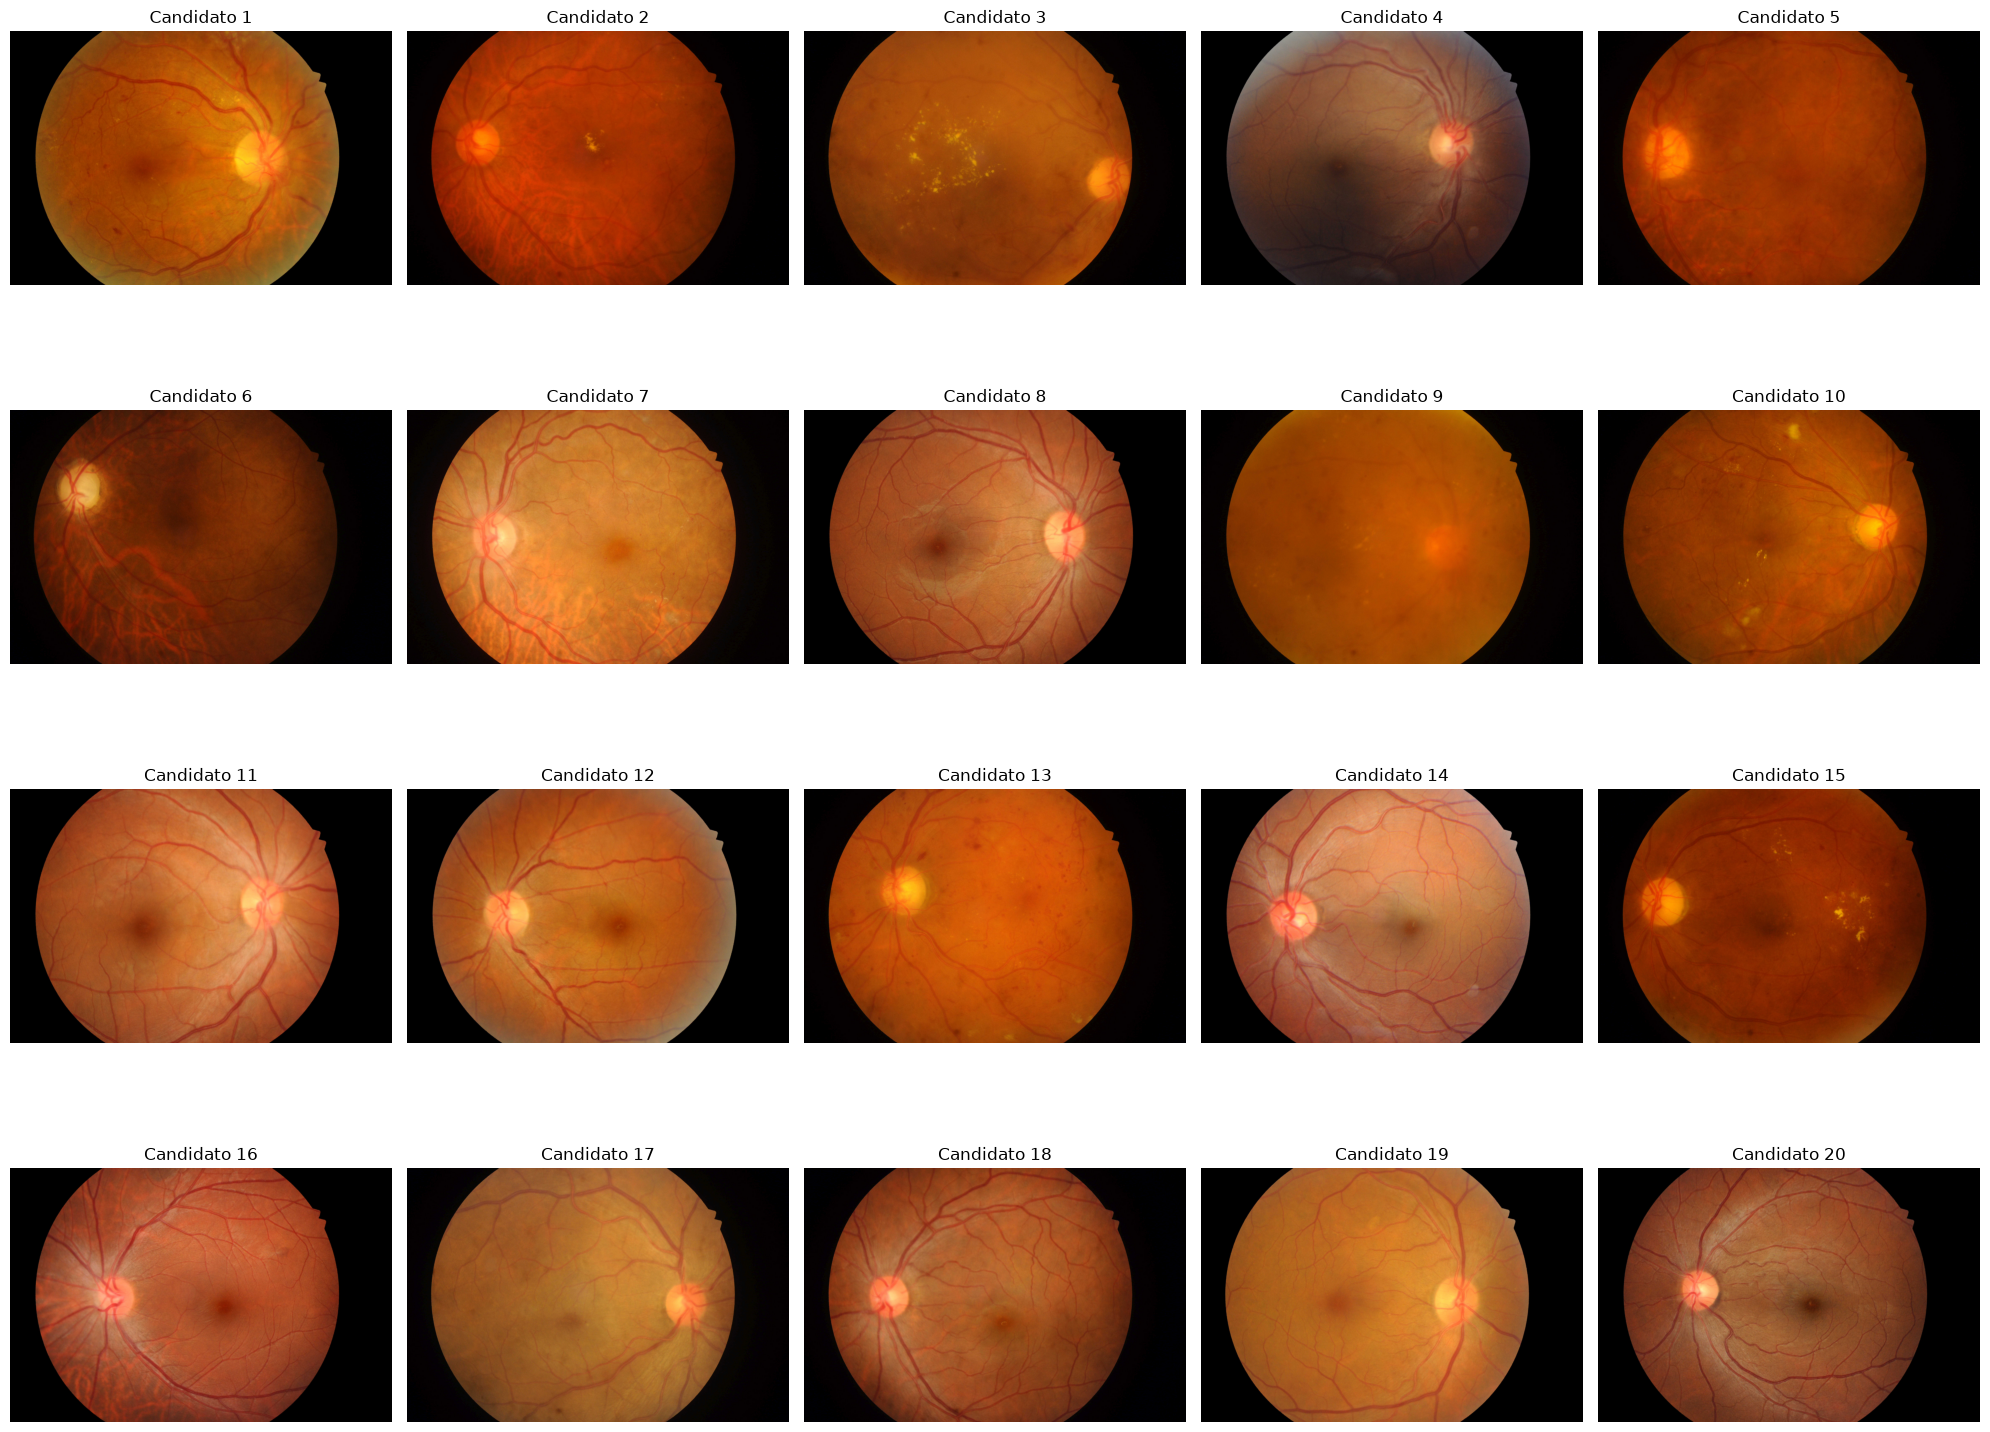


========== RESULTADOS ==========
Total candidatos: 20
Imágenes visualizadas: 20
Imágenes no visualizadas: 0

Estados de las rutas:
estado_ruta
Ruta recuperada    20
Name: count, dtype: int64

Candidatos sin ruta resuelta:


,Image name,image_path,estado_ruta


In [40]:
# ============================================================
# CORREGIR RUTAS Y VISUALIZAR CANDIDATOS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import math
from pathlib import Path
from PIL import Image

# ============================================================
# 1. PREPARAR DATAFRAMES
# ============================================================

candidatos = df_val_split.copy().reset_index(drop=True)
validacion = val_df.copy().reset_index(drop=True)

def normalizar_nombre(valor):
    if pd.isna(valor):
        return ""
    return Path(str(valor).strip()).stem.casefold()

# ============================================================
# 2. CREAR ÍNDICE DE IMÁGENES VERIFICADAS
# ============================================================

indice_imagenes = {}

for _, fila in validacion.iterrows():

    ruta = Path(str(fila["image_path"]))

    if not ruta.is_file():
        continue

    claves = {normalizar_nombre(ruta.name)}

    if "Image name" in validacion.columns:
        claves.add(normalizar_nombre(fila["Image name"]))

    for clave in claves:
        if clave:
            indice_imagenes.setdefault(
                clave, set()
            ).add(str(ruta))

# ============================================================
# 3. RESOLVER RUTAS DE LOS CANDIDATOS
# ============================================================

rutas_corregidas = []
estados = []

for _, fila in candidatos.iterrows():

    ruta_original = Path(str(fila["image_path"]))

    if ruta_original.is_file():

        rutas_corregidas.append(str(ruta_original))
        estados.append("Ruta original válida")
        continue

    claves = {normalizar_nombre(ruta_original.name)}

    if "Image name" in candidatos.columns:
        claves.add(normalizar_nombre(fila["Image name"]))

    coincidencias = set()

    for clave in claves:
        coincidencias.update(
            indice_imagenes.get(clave, set())
        )

    if len(coincidencias) == 1:

        rutas_corregidas.append(
            next(iter(coincidencias))
        )
        estados.append("Ruta recuperada")

    else:

        rutas_corregidas.append(None)

        if len(coincidencias) > 1:
            estados.append("Coincidencia ambigua")
        else:
            estados.append("Sin coincidencia")

candidatos["ruta_corregida"] = rutas_corregidas
candidatos["estado_ruta"] = estados

# ============================================================
# 4. VISUALIZAR LOS CANDIDATOS
# ============================================================

lista_de_Prueba = []
nombre_Imagenes = []

n_images = len(candidatos)

if n_images == 0:
    raise ValueError("No hay candidatos para visualizar.")

cols = 5
rows = math.ceil(n_images / cols)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(20, 4 * rows),
    squeeze=False
)

errores_lectura = []

for i, fila in candidatos.iterrows():

    ax = axes[i // cols, i % cols]
    ruta = fila["ruta_corregida"]

    if ruta is not None:

        try:
            with Image.open(ruta) as imagen:
                img = imagen.convert("RGB")
                ax.imshow(img)

            lista_de_Prueba.append(ruta)
            nombre_Imagenes.append(Path(ruta).stem)

        except Exception as error:

            errores_lectura.append(
                (ruta, str(error))
            )

            ax.text(
                0.5, 0.5,
                "Error de lectura",
                ha="center",
                va="center",
                transform=ax.transAxes
            )

    else:

        ax.text(
            0.5, 0.5,
            "Imagen no encontrada",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

    ax.set_title(f"Candidato {i + 1}")
    ax.axis("off")

for j in range(n_images, rows * cols):
    axes[j // cols, j % cols].axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 5. MOSTRAR RESULTADOS
# ============================================================

print("\n========== RESULTADOS ==========")
print("Total candidatos:", n_images)
print("Imágenes visualizadas:", len(lista_de_Prueba))
print("Imágenes no visualizadas:",
      n_images - len(lista_de_Prueba))

print("\nEstados de las rutas:")
print(candidatos["estado_ruta"].value_counts())

print("\nCandidatos sin ruta resuelta:")

display(
    candidatos.loc[
        candidatos["ruta_corregida"].isna(),
        ["Image name", "image_path", "estado_ruta"]
    ]
    if "Image name" in candidatos.columns
    else candidatos.loc[
        candidatos["ruta_corregida"].isna(),
        ["image_path", "estado_ruta"]
    ]
)

if errores_lectura:
    print("\nErrores de lectura:")
    for ruta, error in errores_lectura:
        print(ruta, "->", error)

In [41]:


# CAMBIAR ESTA RUTA por la carpeta que contiene
# las imágenes que quieres clasificar.
PREDICT_DIR = Path(
    "/data/IDRiD2/IDRiD/test/images"
)

PREDICT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def collect_prediction_images(path):
    if path.is_file():
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            return [path]

        return []

    if not path.exists():
        return []

    return sorted(
        [
            image_path
            for image_path in path.rglob("*")
            if (
                image_path.is_file()
                and image_path.suffix.lower()
                in IMAGE_EXTENSIONS
            )
        ]
    )


def decode_inference_image(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0,
    )

    return tf.cast(image, tf.uint8)


prediction_paths = collect_prediction_images(
    PREDICT_DIR

    )

#Aqui estoy pasando las imagenes aleatoria que ya filtré arriba
prediction_paths = lista_de_Prueba


print(
    "Imágenes encontradas:",
    len(prediction_paths),
)

external_predictions_df = pd.DataFrame()

AUTOTUNE = tf.data.AUTOTUNE

if prediction_paths:
    prediction_dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            [str(path) for path in prediction_paths]
        )
        .map(
            decode_inference_image,
            num_parallel_calls=AUTOTUNE,
        )
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    external_probabilities = (
        loaded_model.predict(
            prediction_dataset,
            verbose=1,
        )
        .reshape(-1)
    )

    external_labels = (
        external_probabilities
        >= LOADED_THRESHOLD
    ).astype(int)



    external_predictions_df = pd.DataFrame({
        "image": [
            nombre for nombre in nombre_Imagenes
        ],
        "image_path": [
            str(path)
            for path in prediction_paths
        ],
        "probability_referable": external_probabilities,
        "predicted_label": external_labels,
        "predicted_class": [
            CLASS_NAMES[int(label)]
            for label in external_labels
        ],
        "confidence": [
            probability
            if label == 1
            else 1.0 - probability
            for probability, label
            in zip(
                external_probabilities,
                external_labels,
            )
        ],
        "Valor Verdadero":[
            valor for valor in df_val_split['binary_label']
        ],
    })

    WORK_ROOT = Path.cwd()
    RUN_DIR = WORK_ROOT / "ResNet50"

    external_output_path = (
        RUN_DIR
        / "predicciones_imagenes_externas.csv"
    )

    external_predictions_df.to_csv(
        external_output_path,
        index=False,
    )

    display(external_predictions_df)

    print(
        "Resultados guardados en:",
        external_output_path,
    )

else:
    print(
        "La carpeta está vacía. Agrega imágenes "
        "y vuelve a ejecutar esta celda."
    )



Imágenes encontradas: 20


NameError: name 'loaded_model' is not defined

# Visualizacion De las Predicciones

In [42]:

if not external_predictions_df.empty:
    number_to_show = min(
        20,
        len(external_predictions_df),
    )

    selected_rows = (
        external_predictions_df
        .head(number_to_show)
    )

    columns = 4
    rows = math.ceil(
        number_to_show / columns
    )

    plt.figure(
        figsize=(16, rows * 4)
    )

    for plot_index, (_, row) in enumerate(
        selected_rows.iterrows(),
        start=1,
    ):
        image = keras.utils.load_img(
            row["image_path"]
        )

        plt.subplot(
            rows,
            columns,
            plot_index,
        )

        plt.imshow(image)

        # Determinar si la predicción es correcta para el color
        es_correcto = int(row['predicted_label']) == int(row['Valor Verdadero'])
        color_titulo = "green" if es_correcto else "red"

        plt.title(
            f"{row['predicted_class']}\n"
            f"Probabilidad de Referible: "
            f"{row['probability_referable']:.3f}\n"
            f"Valor Real: {row['Valor Verdadero']}",
            color=color_titulo
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


#  GRAD-CAM


ADVERTENCIA: No se encontró LOADED_THRESHOLD. Se utilizará 0.5.
Modelo: ResNet50_Clinical_DR
Umbral: 0.5

Imagen seleccionada:
data\IDRiD2\IDRiD\train\images\IDRiD_003.jpg


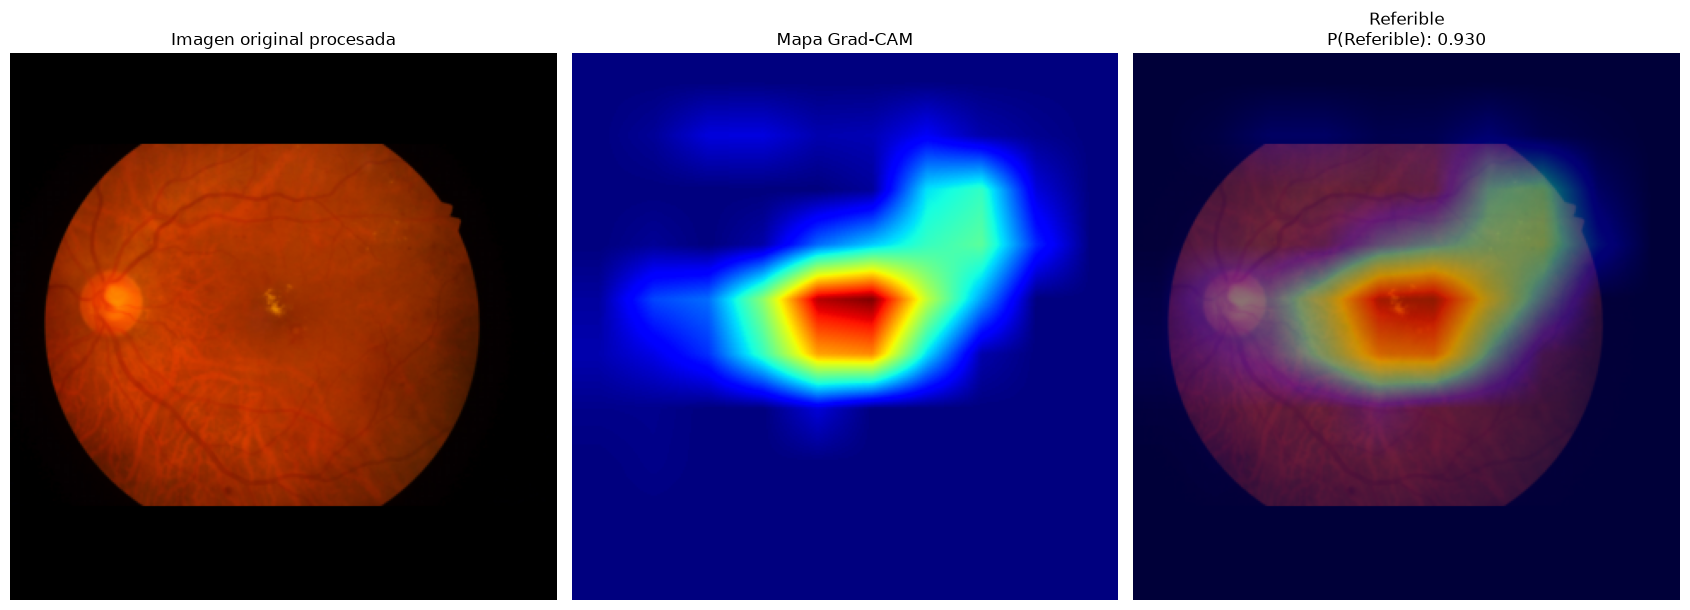


========== RESULTADO GRAD-CAM ==========
Clase predicha: Referible
Probabilidad referible: 0.9303
Umbral utilizado: 0.5
Magnitud media del gradiente: 0.00022137437190394849
Rango del mapa: 0.0 - 0.9955

GRAD-CAM FINALIZADO


In [44]:

# ============================================================
# GRAD-CAM - RESNET50 CLINICAL DR
# CLASIFICACIÓN BINARIA DE RETINOPATÍA DIABÉTICA
# ============================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

BACKBONE_NAME = "resnet50"
LAST_CONV_LAYER = "conv5_block3_out"

# Obtener el modelo cargado
if "loaded_model" in globals():
    modelo_gradcam = loaded_model

elif "model" in globals():
    modelo_gradcam = model

else:
    raise ValueError(
        "No se encontró un modelo cargado. "
        "Primero debes cargar ResNet50."
    )

# Obtener umbral de clasificación
if "LOADED_THRESHOLD" in globals():
    THRESHOLD = float(LOADED_THRESHOLD)
else:
    THRESHOLD = 0.5
    print(
        "ADVERTENCIA: No se encontró LOADED_THRESHOLD. "
        "Se utilizará 0.5."
    )

if not 0 <= THRESHOLD <= 1:
    raise ValueError("El umbral debe estar entre 0 y 1.")

print("Modelo:", modelo_gradcam.name)
print("Umbral:", THRESHOLD)

# ============================================================
# 2. CARGAR IMAGEN
# ============================================================

def load_gradcam_image(image_path):

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Imagen no encontrada: {image_path}"
        )

    # Mantener la función usada en el pipeline original
    image, _ = decode_and_resize(
        tf.constant(str(image_path)),
        tf.constant(0.0),
    )

    image = tf.cast(image, tf.float32)

    return image


# ============================================================
# 3. GENERAR GRAD-CAM
# ============================================================

def generate_gradcam(
    image_path,
    model,
    threshold=0.5,
    backbone_name="resnet50",
    last_conv_layer_name="conv5_block3_out",
):

    # --------------------------------------------------------
    # A. CARGAR IMAGEN
    # --------------------------------------------------------

    image = load_gradcam_image(image_path)

    image_batch = tf.expand_dims(
        image,
        axis=0,
    )

    # IMPORTANTE:
    # Conservar el preprocesamiento usado durante entrenamiento.
    # Esta línea reproduce el preprocesamiento de tu celda
    # original. No aplicarlo dos veces si ya está integrado.

    preprocessed = (
        tf.keras.applications.resnet50.preprocess_input(
            tf.identity(image_batch)
        )
    )

    # --------------------------------------------------------
    # B. LOCALIZAR BACKBONE
    # --------------------------------------------------------

    try:
        backbone_model = model.get_layer(
            backbone_name
        )

    except ValueError:

        print("\nCapas disponibles:")

        for layer in model.layers:
            print(layer.name)

        raise ValueError(
            f"No se encontró el backbone '{backbone_name}'."
        )

    try:
        conv_layer = backbone_model.get_layer(
            last_conv_layer_name
        )

    except ValueError:

        raise ValueError(
            f"No se encontró la capa "
            f"'{last_conv_layer_name}' "
            f"dentro de {backbone_model.name}."
        )

    # --------------------------------------------------------
    # C. MODELO PARA EXTRAER CARACTERÍSTICAS
    # --------------------------------------------------------

    grad_backbone = keras.Model(
        inputs=backbone_model.inputs,
        outputs=[
            conv_layer.output,
            backbone_model.output,
        ],
    )

    # --------------------------------------------------------
    # D. CABEZA DE CLASIFICACIÓN
    # --------------------------------------------------------

    head_layers = [
        "global_average_pooling",
        "head_dropout",
        "dense_256",
        "bn_256",
        "dropout_256",
        "dense_128",
        "bn_128",
        "dropout_128",
        "dense_64",
        "bn_64",
        "dropout_64",
    ]

    capas = []

    for nombre in head_layers:

        try:
            capas.append(
                model.get_layer(nombre)
            )

        except ValueError:

            raise ValueError(
                f"No se encontró la capa '{nombre}'. "
                "Verifica model.summary()."
            )

    prediction_layer = model.get_layer(
        "prediction"
    )

    if (
        getattr(
            prediction_layer.activation,
            "__name__",
            "",
        ) != "sigmoid"
    ):
        raise ValueError(
            "La capa prediction debe usar sigmoid."
        )

    # --------------------------------------------------------
    # E. CALCULAR GRADIENTES
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        conv_output, features = grad_backbone(
            preprocessed,
            training=False,
        )

        x = features

        # Reconstruir el orden exacto de la cabeza
        for layer in capas:

            if isinstance(
                layer,
                keras.layers.Dropout
            ):
                x = layer(
                    x,
                    training=False,
                )

            elif isinstance(
                layer,
                keras.layers.BatchNormalization
            ):
                x = layer(
                    x,
                    training=False,
                )

            else:
                x = layer(x)

        # Probabilidad de clasificación
        probability = prediction_layer(x)

        # Logit antes de la sigmoide
        logits = tf.linalg.matmul(
            x,
            prediction_layer.kernel,
        )

        if prediction_layer.use_bias:
            logits = logits + prediction_layer.bias

        # Si es referible: gradiente positivo
        # Si es no referible: gradiente negativo
        target_score = tf.where(
            probability[:, 0] >= threshold,
            logits[:, 0],
            -logits[:, 0],
        )

    gradients = tape.gradient(
        target_score,
        conv_output,
    )

    if gradients is None:
        raise RuntimeError(
            "No se pudieron calcular los gradientes. "
            "Revisa la conexión entre el backbone "
            "y la cabeza de clasificación."
        )

    # --------------------------------------------------------
    # F. CALCULAR PESOS DE CANALES
    # --------------------------------------------------------

    channel_weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
    )

    # --------------------------------------------------------
    # G. GENERAR MAPA DE CALOR
    # --------------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_output
        * channel_weights[:, None, None, :],
        axis=-1,
    )

    heatmap = tf.nn.relu(
        heatmap
    )

    max_heatmap = tf.reduce_max(heatmap)

    if float(max_heatmap.numpy()) <= 1e-8:
        print(
            "ADVERTENCIA: Grad-CAM tiene activación "
            "positiva casi nula."
        )

    heatmap = heatmap / (
        max_heatmap
        + tf.keras.backend.epsilon()
    )

    # --------------------------------------------------------
    # H. REDIMENSIONAR A TAMAÑO DE IMAGEN
    # --------------------------------------------------------

    image_height = tf.shape(image)[0]
    image_width = tf.shape(image)[1]

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        size=[image_height, image_width],
        method="bilinear",
    )

    heatmap = heatmap[0, :, :, 0].numpy()

    # --------------------------------------------------------
    # I. RECUPERAR IMAGEN RGB
    # --------------------------------------------------------

    image_array = image.numpy()

    # Ajustar únicamente la imagen de visualización
    if (
        image_array.min() >= 0
        and image_array.max() <= 1.0
    ):
        image_array = image_array * 255.0

    image_array = np.clip(
        image_array,
        0,
        255,
    ).astype(np.uint8)

    # --------------------------------------------------------
    # J. MAPA A COLOR
    # --------------------------------------------------------

    color_map = plt.get_cmap("jet")

    colored_heatmap = (
        color_map(heatmap)[..., :3] * 255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # K. SUPERPOSICIÓN
    # --------------------------------------------------------

    alpha = 0.45

    overlay = np.clip(
        image_array.astype(np.float32) * (1 - alpha)
        + colored_heatmap.astype(np.float32) * alpha,
        0,
        255,
    ).astype(np.uint8)

    # --------------------------------------------------------
    # L. RESULTADO DE CLASIFICACIÓN
    # --------------------------------------------------------

    probability_value = float(
        probability[0, 0].numpy()
    )

    predicted_class = int(
        probability_value >= threshold
    )

    return {
        "image": image_array,
        "heatmap": heatmap,
        "overlay": overlay,
        "probability": probability_value,
        "predicted_class": predicted_class,
        "predicted_name": CLASS_NAMES[
            predicted_class
        ],
        "gradients_mean": float(
            tf.reduce_mean(
                tf.abs(gradients)
            ).numpy()
        ),
    }


# ============================================================
# 4. SELECCIONAR UNA IMAGEN VÁLIDA DE VALIDACIÓN
# ============================================================

# Se usan rutas previamente verificadas
rutas_validacion = [
    Path(str(p))
    for p in val_df["image_path"]
    if Path(str(p)).is_file()
]

if not rutas_validacion:
    raise FileNotFoundError(
        "No se encontraron imágenes de validación."
    )

gradcam_example_path = rutas_validacion[0]

print("\nImagen seleccionada:")
print(gradcam_example_path)

# ============================================================
# 5. GENERAR GRAD-CAM
# ============================================================

gradcam_result = generate_gradcam(
    image_path=gradcam_example_path,
    model=modelo_gradcam,
    threshold=THRESHOLD,
    backbone_name=BACKBONE_NAME,
    last_conv_layer_name=LAST_CONV_LAYER,
)

# ============================================================
# 6. VISUALIZAR RESULTADOS
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 6),
)

# Imagen
axes[0].imshow(
    gradcam_result["image"]
)
axes[0].set_title("Imagen original procesada")
axes[0].axis("off")

# Grad-CAM
axes[1].imshow(
    gradcam_result["heatmap"],
    cmap="jet",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Mapa Grad-CAM")
axes[1].axis("off")

# Superposición
axes[2].imshow(
    gradcam_result["overlay"]
)

axes[2].set_title(
    f"{gradcam_result['predicted_name']}\n"
    f"P(Referible): "
    f"{gradcam_result['probability']:.3f}"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 7. DIAGNÓSTICO
# ============================================================

print("\n========== RESULTADO GRAD-CAM ==========")

print(
    "Clase predicha:",
    gradcam_result["predicted_name"]
)

print(
    "Probabilidad referible:",
    round(gradcam_result["probability"], 4)
)

print(
    "Umbral utilizado:",
    THRESHOLD
)

print(
    "Magnitud media del gradiente:",
    gradcam_result["gradients_mean"]
)

print(
    "Rango del mapa:",
    round(float(gradcam_result["heatmap"].min()), 4),
    "-",
    round(float(gradcam_result["heatmap"].max()), 4),
)

print("\nGRAD-CAM FINALIZADO")


In [45]:
'''
CLASS_NAMES = {
    0: "No referible",
    1: "Referible",
}

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)


def load_gradcam_image(image_path):
    image_bytes = tf.io.read_file(
        str(image_path)
    )

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH,
        method="bilinear",
        antialias=True,
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0,
    )

    return tf.cast(image, tf.float32)


def generate_gradcam(
    image_path,
    model,
    threshold,
    backbone_name="efficientnetb0",
    last_conv_layer_name="top_activation", # Mejorado: usa la activacion tras el BN
):
    image = load_gradcam_image(
        image_path
    )

    image_batch = tf.expand_dims(
        image,
        axis=0,
    )

    backbone_model = model.get_layer(
        backbone_name
    )

    grad_backbone = keras.Model(
        inputs=backbone_model.input,
        outputs=[
            backbone_model.get_layer(
                last_conv_layer_name
            ).output,
            backbone_model.output,
        ],
    )

    gap_layer = model.get_layer("gap")
    dropout_layer = model.get_layer(
        "head_dropout"
    )

    # Get intermediate layers added to the head
    # Using the correct layer names as seen in the model summary
    dense_layer_0 = model.get_layer("dense_18")
    dropout_layer_1 = model.get_layer("dropout_18")
    dense_layer_1 = model.get_layer("dense_19")
    dropout_layer_2 = model.get_layer("dropout_19")
    dense_layer_2 = model.get_layer("dense_20")
    dropout_layer_3 = model.get_layer("dropout_20")

    prediction_layer = model.get_layer(
        "prediction"
    )

    with tf.GradientTape() as tape:
        conv_output, final_features = grad_backbone(
            image_batch,
            training=False,
        )

        x = gap_layer(final_features)
        x = dropout_layer(
            x,
            training=False,
        )

        # Apply intermediate layers
        x = dense_layer_0(x)
        x = dropout_layer_1(x, training=False)
        x = dense_layer_1(x)
        x = dropout_layer_2(x, training=False)
        x = dense_layer_2(x)
        x = dropout_layer_3(x, training=False)

        probability = prediction_layer(x)

        predicted_class = int(
            probability[0, 0].numpy()
            >= threshold
        )

        if predicted_class == 1:
            target_score = probability[:, 0]
        else:
            target_score = 1.0 - probability[:, 0]

    gradients = tape.gradient(
        target_score,
        conv_output,
    )

    channel_weights = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2),
    )

    conv_output = conv_output[0]

    heatmap = tf.reduce_sum(
        conv_output
        * channel_weights,
        axis=-1,
    )

    heatmap = tf.maximum(
        heatmap,
        0,
    )

    # Evitar divisiones por cero
    heatmap_max = tf.reduce_max(heatmap)
    if heatmap_max != 0:
        heatmap = heatmap / heatmap_max

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        IMG_SIZE,
    )[..., 0]

    heatmap = heatmap.numpy()

    image_array = image.numpy().astype(
        np.uint8
    )

    color_map = plt.get_cmap("jet")

    colored_heatmap = (
        color_map(heatmap)[..., :3] * 255
    ).astype(np.uint8)

    alpha = 0.50 # Aumentado ligeramente para mayor contraste

    overlay = np.clip(
        image_array * (1 - alpha)
        + colored_heatmap * alpha,
        0,
        255,
    ).astype(np.uint8)

    probability_value = float(
        probability[0, 0].numpy()
    )

    return {
        "image": image_array,
        "heatmap": heatmap,
        "overlay": overlay,
        "probability": probability_value,
        "predicted_class": predicted_class,
        "predicted_name": CLASS_NAMES[
            predicted_class
        ],
    }


if prediction_paths:
    gradcam_example_path = prediction_paths[0]
else:
    gradcam_example_path = Path(
        val_df.iloc[0]["image_path"]
    )

gradcam_result = generate_gradcam(
    image_path=gradcam_example_path,
    model=loaded_model,
    threshold=LOADED_THRESHOLD,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 6),
)

axes[0].imshow(
    gradcam_result["image"]
)

axes[0].set_title("Imagen procesada")
axes[0].axis("off")

axes[1].imshow(
    gradcam_result["heatmap"],
    cmap="jet",
)

axes[1].set_title("Mapa Grad-CAM")
axes[1].axis("off")

axes[2].imshow(
    gradcam_result["overlay"]
)

axes[2].set_title(
    f"{gradcam_result['predicted_name']}\n"
    f"P(Referible): "
    f"{gradcam_result['probability']:.3f}"
)

axes[2].axis("off")

plt.tight_layout()
plt.show()'''

'\nCLASS_NAMES = {\n    0: "No referible",\n    1: "Referible",\n}\n\nIMG_HEIGHT = 224\nIMG_WIDTH = 224\nIMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)\n\n\ndef load_gradcam_image(image_path):\n    image_bytes = tf.io.read_file(\n        str(image_path)\n    )\n\n    image = tf.io.decode_image(\n        image_bytes,\n        channels=3,\n        expand_animations=False,\n    )\n\n    image.set_shape([None, None, 3])\n\n    image = tf.image.resize_with_pad(\n        image,\n        IMG_HEIGHT,\n        IMG_WIDTH,\n        method="bilinear",\n        antialias=True,\n    )\n\n    image = tf.clip_by_value(\n        image,\n        0.0,\n        255.0,\n    )\n\n    return tf.cast(image, tf.float32)\n\n\ndef generate_gradcam(\n    image_path,\n    model,\n    threshold,\n    backbone_name="efficientnetb0",\n    last_conv_layer_name="top_activation", # Mejorado: usa la activacion tras el BN\n):\n    image = load_gradcam_image(\n        image_path\n    )\n\n    image_batch = tf.expand_dims(\n        ima


# DASHBOARD


In [46]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

dashboard = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[
        "Pérdida",
        "ROC AUC",
        "PR AUC",
        "Matriz de confusión",
        "Curva ROC",
        "Métricas principales",
    ],
)

# Pérdida
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["loss"],
        mode="lines",
        name="Loss entrenamiento",
    ),
    row=1,
    col=1,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_loss"],
        mode="lines",
        name="Loss validación",
    ),
    row=1,
    col=1,
)

# ROC AUC
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["auc"], # Corregido a "auc"
        mode="lines",
        name="ROC AUC entrenamiento",
    ),
    row=1,
    col=2,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_auc"], # Corregido a "val_auc"
        mode="lines",
        name="ROC AUC validación",
    ),
    row=1,
    col=2,
)

# PR AUC
dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["pr_auc"], # Corregido a "pr_auc"
        mode="lines",
        name="PR AUC entrenamiento",
    ),
    row=1,
    col=3,
)

dashboard.add_trace(
    go.Scatter(
        x=history_df["epoch"],
        y=history_df["val_pr_auc"], # Corregido a "val_pr_auc"
        mode="lines",
        name="PR AUC validación",
    ),
    row=1,
    col=3,
)

# Matriz de confusión
dashboard.add_trace(
    go.Heatmap(
        z=cm_selected,
        x=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        y=[
            CLASS_NAMES[0],
            CLASS_NAMES[1],
        ],
        text=cm_selected,
        texttemplate="%{text}",
        showscale=False,
        name="Confusión",
    ),
    row=2,
    col=1,
)

# Curva ROC
dashboard.add_trace(
    go.Scatter(
        x=fpr_curve,
        y=tpr_curve,
        mode="lines",
        name="ROC",
    ),
    row=2,
    col=2,
)

dashboard.add_trace(
    go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        line=dict(dash="dash"),
        name="Clasificador aleatorio",
    ),
    row=2,
    col=2,
)

# Barras de métricas
metric_names = [
    "Accuracy",
    "Precisión",
    "Sensibilidad",
    "Especificidad",
    "F1",
]

metric_values = [
    metrics_selected["accuracy"],
    metrics_selected["precision"],
    metrics_selected["sensitivity_recall"],
    metrics_selected["specificity"],
    metrics_selected["f1_score"],
]

dashboard.add_trace(
    go.Bar(
        x=metric_names,
        y=metric_values,
        text=[
            f"{value:.3f}"
            for value in metric_values
        ],
        textposition="auto",
        name="Métricas",
    ),
    row=2,
    col=3,
)

dashboard.update_yaxes(
    range=[0, 1],
    row=2,
    col=3,
)

dashboard.update_layout(
    title=(
        "Dashboard ResNet50 — " # Actualizado a ResNet50
        "Retinopatía diabética referible"
    ),
    height=850,
    width=1500,
    template="plotly_white",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.18,
        xanchor="center",
        x=0.5,
    ),
)

dashboard.show()

dashboard.write_html(
    str(DASHBOARD_PATH)
)

print(
    "Dashboard guardado en:",
    DASHBOARD_PATH,
)


Dashboard guardado en: c:\Users\lauri\Documents\PROYECTO_FINAL\ResNet50\dashboard_resnet50.html


### Informe de Rendimiento Detallado

In [47]:
from IPython.display import display, Markdown

report = "# Informe de Rendimiento del Modelo ResNet50\n\n"
report += "El siguiente informe presenta las métricas obtenidas con el conjunto de validación bajo diferentes configuraciones de umbral.\n\n"

for index, row in metrics_comparison.iterrows():
    report += f"## 🔹 Configuración: {row['Configuración']}\n"
    report += f"- **Umbral de Decisión:** `{row['threshold']:.4f}`\n"
    report += f"- **Exactitud (Accuracy):** {row['accuracy']:.4f}\n"
    report += f"- **Precisión (Precision):** {row['precision']:.4f}\n"
    report += f"- **Sensibilidad (Recall):** {row['sensitivity_recall']:.4f}\n"
    report += f"- **Especificidad:** {row['specificity']:.4f}\n"
    report += f"- **F1-Score:** {row['f1_score']:.4f}\n"
    report += f"- **ROC AUC:** {row['roc_auc']:.4f}\n"
    report += f"- **PR AUC:** {row['pr_auc']:.4f}\n"

    report += "\n**Matriz de Confusión Desglosada:**\n"
    report += f"- Verdaderos Negativos (TN): **{row['true_negatives']}** (No Referibles clasificados correctamente)\n"
    report += f"- Falsos Positivos (FP): **{row['false_positives']}** (No Referibles clasificados erróneamente como Referibles)\n"
    report += f"- Falsos Negativos (FN): **{row['false_negatives']}** (Referibles clasificados erróneamente como No Referibles)\n"
    report += f"- Verdaderos Positivos (TP): **{row['true_positives']}** (Referibles clasificados correctamente)\n\n"
    report += "---\n\n"

display(Markdown(report))


# Informe de Rendimiento del Modelo ResNet50

El siguiente informe presenta las métricas obtenidas con el conjunto de validación bajo diferentes configuraciones de umbral.

## 🔹 Configuración: Umbral 0.50
- **Umbral de Decisión:** `0.5000`
- **Exactitud (Accuracy):** 0.9277
- **Precisión (Precision):** 0.9259
- **Sensibilidad (Recall):** 0.9615
- **Especificidad:** 0.8710
- **F1-Score:** 0.9434
- **ROC AUC:** 0.9876
- **PR AUC:** 0.9931

**Matriz de Confusión Desglosada:**
- Verdaderos Negativos (TN): **27** (No Referibles clasificados correctamente)
- Falsos Positivos (FP): **4** (No Referibles clasificados erróneamente como Referibles)
- Falsos Negativos (FN): **2** (Referibles clasificados erróneamente como No Referibles)
- Verdaderos Positivos (TP): **50** (Referibles clasificados correctamente)

---

## 🔹 Configuración: Mejor F1
- **Umbral de Decisión:** `0.6315`
- **Exactitud (Accuracy):** 0.9398
- **Precisión (Precision):** 0.9608
- **Sensibilidad (Recall):** 0.9423
- **Especificidad:** 0.9355
- **F1-Score:** 0.9515
- **ROC AUC:** 0.9876
- **PR AUC:** 0.9931

**Matriz de Confusión Desglosada:**
- Verdaderos Negativos (TN): **29** (No Referibles clasificados correctamente)
- Falsos Positivos (FP): **2** (No Referibles clasificados erróneamente como Referibles)
- Falsos Negativos (FN): **3** (Referibles clasificados erróneamente como No Referibles)
- Verdaderos Positivos (TP): **49** (Referibles clasificados correctamente)

---

## 🔹 Configuración: Sensibilidad >= 90 %
- **Umbral de Decisión:** `0.6933`
- **Exactitud (Accuracy):** 0.9398
- **Precisión (Precision):** 1.0000
- **Sensibilidad (Recall):** 0.9038
- **Especificidad:** 1.0000
- **F1-Score:** 0.9495
- **ROC AUC:** 0.9876
- **PR AUC:** 0.9931

**Matriz de Confusión Desglosada:**
- Verdaderos Negativos (TN): **31** (No Referibles clasificados correctamente)
- Falsos Positivos (FP): **0** (No Referibles clasificados erróneamente como Referibles)
- Falsos Negativos (FN): **5** (Referibles clasificados erróneamente como No Referibles)
- Verdaderos Positivos (TP): **47** (Referibles clasificados correctamente)

---

